# Phase 1 驗收：台股資料品質檢驗

這份 notebook 是 Phase 1（資料基礎設施）的驗收品，要回答一個問題：

> **自建的這個資料庫，裡面的資料可以拿來做回測嗎？**

不是「有沒有抓到資料」，而是「抓到的資料撐不撐得住後面的研究」。所以除了畫價格圖，
更重要的是把**已知的缺陷攤開來講**——哪些資料被擋掉、為什麼、剩下的能信到什麼程度。

檢查五件事：

1. 原始價 vs 還原價：除權息造成的跳空有沒有被填平
2. 成交量
3. 基本統計與年化波動率
4. 全 universe 的資料覆蓋率（起訖日、缺漏天數）
5. 隔離區（quarantine）統計：被擋下來的資料是什麼、為什麼

**資料怎麼來的**：`python -m ingestion.run_ingest --mode sample`
（pipeline 說明見 `README.md`，資料來源的選型與已知限制見 `docs/data_source.md`）

In [1]:
import sys
from pathlib import Path

# 讓 notebook 不管從哪裡開啟都找得到專案模組
ROOT = Path.cwd()
while not (ROOT / "config" / "settings.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from database.connection import get_connection
from database.data_access import get_price_matrix, get_prices, get_universe

# 中文標題要指定字型，否則會變成一堆方框
plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

conn = get_connection()
print(f"資料庫: {ROOT / 'database' / 'quant.db'}")

資料庫: C:\Users\user\Documents\GitHub\Taiwan-Quant-Research\database\quant.db


## 1. 資料庫總覽

先確認手上有什麼。五張表各自的角色：

| 表 | 存什麼 | 為什麼需要 |
|---|---|---|
| `stocks` | 股票基本資料、是否還在市場上 | `is_active` 用來避免存活者偏誤 |
| `prices` | **原始**日線 OHLCV（不含還原價） | 原始成交價是不會變的事實 |
| `dividend_events` | 除權息事件 | 還原價的輸入之一 |
| `corporate_actions` | 減資、面額變更 | 還原價的輸入之二 |
| `data_quarantine` | 被擋下或被標記的資料 | 資料品質的稽核軌跡 |

**還原價不存在資料庫裡**，是讀取時用 `dividend_events` + `corporate_actions` 即時算的。
理由：後還原的調整因子取決於「這一天之後發生過哪些事件」，每次除權息都會讓更早的
還原價全部過期，而增量更新不會回頭改歷史列。

In [2]:
tables = ["stocks", "prices", "dividend_events", "corporate_actions",
          "ingest_log", "data_quarantine"]
overview = pd.DataFrame(
    [{"表": t, "列數": conn.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]}
     for t in tables]
).set_index("表")

stocks, rows, first, last = conn.execute(
    "SELECT COUNT(DISTINCT stock_id), COUNT(*), MIN(date), MAX(date) FROM prices"
).fetchone()

print(f"涵蓋 {stocks} 檔股票，{rows:,} 列日線，日期範圍 {first} ~ {last}")
print(f"投資範圍（universe）: {len(get_universe())} 檔仍在市場上")
overview

涵蓋 38 檔股票，104,702 列日線，日期範圍 2015-01-05 ~ 2026-09-18
投資範圍（universe）: 38 檔仍在市場上


,列數
表,
stocks,38
prices,104702
dividend_events,465
corporate_actions,14
ingest_log,38
data_quarantine,440


## 2. 單一股票檢視

規劃書對 Phase 1 的完成標準是：

> 輸入股票代碼，能從資料庫撈出歷史資料並畫出價格、成交量、基本統計。

改下面這一行就能換股票。幾個值得看的：

- `2330` 台積電：事件最多（34 次除權息），適合看還原價的累積效果
- `2609` 陽明：2017 年減資，原始價單日 +116%
- `6919` 康霈：2025 年面額變更，原始價單日 −89%
- `2409` 友達：連續三年的股利全部配在公積，是踩過的坑之一

In [3]:
STOCK_ID = "2330"

name = conn.execute("SELECT name FROM stocks WHERE stock_id = ?", (STOCK_ID,)).fetchone()[0]
df = get_prices(STOCK_ID)

print(f"{STOCK_ID} {name}：{len(df):,} 個交易日，{df.index[0].date()} ~ {df.index[-1].date()}")
df.tail(3)

2330 台積電：2,855 個交易日，2015-01-05 ~ 2026-09-18


,open,high,low,close,volume,turnover,adj_open,adj_high,adj_low,adj_close
date,,,,,,,,,,
2026-09-16,2375.0,2395.0,2375.0,2380.0,20919285,4.981287e+10,2375.0,2395.0,2375.0,2380.0
2026-09-17,2405.0,2445.0,2400.0,2425.0,18116974,4.393323e+10,2405.0,2445.0,2400.0,2425.0
2026-09-18,2460.0,2460.0,2435.0,2460.0,40892688,1.003941e+11,2460.0,2460.0,2435.0,2460.0


### 2.1 原始價 vs 還原價

**這張圖是整個 Phase 1 的重點。**

紅色虛線是除權息 / 減資日。在那些日子上，藍線（原始價）會出現向下的缺口——
那不是虧損，是股利發到股東手上、價格相應調整。橘線（還原價）把這些缺口填平，
所以它的每一段漲跌才是投資人真正的報酬。

**回測算報酬一定要用 `adj_close`；要畫「當時市場上看到的價格」才用 `close`。**

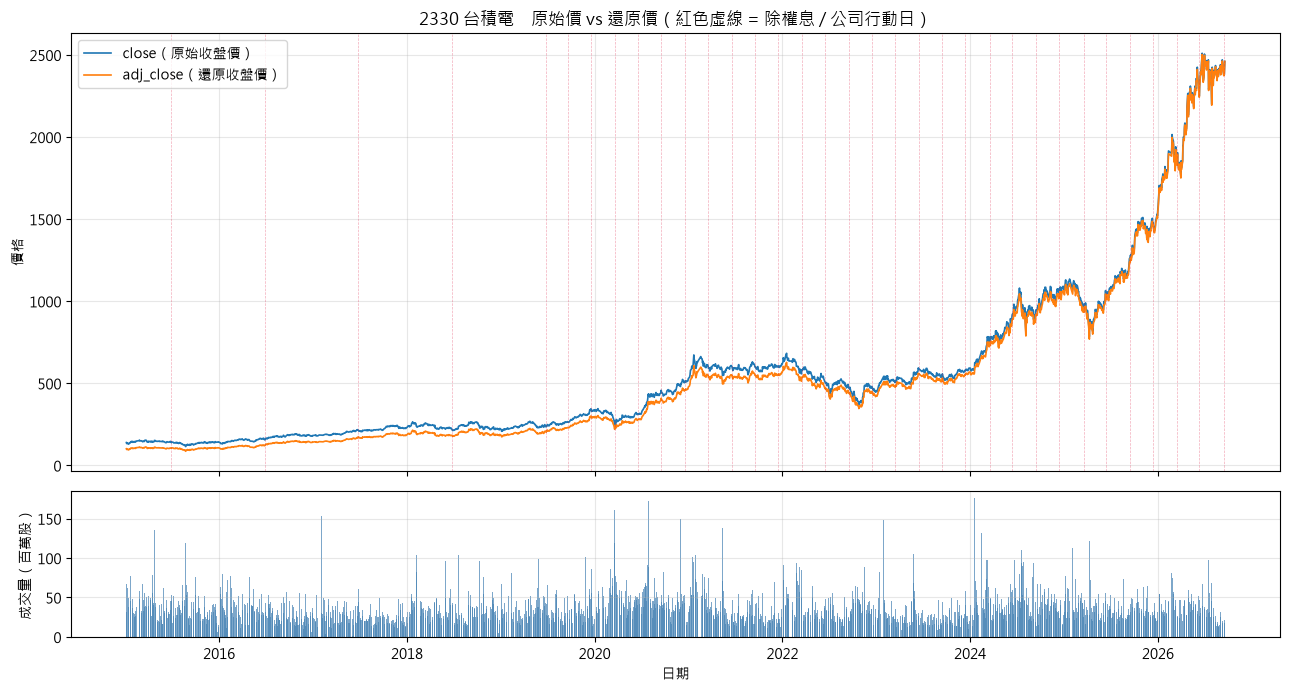

期間內共 34 次事件：
kind
除權息    34


In [4]:
events = pd.read_sql(
    """
    SELECT ex_date AS date, '除權息' AS kind FROM dividend_events WHERE stock_id = :sid
    UNION ALL
    SELECT ex_date AS date, action_type AS kind FROM corporate_actions WHERE stock_id = :sid
    """,
    conn, params={"sid": STOCK_ID},
)
events["date"] = pd.to_datetime(events["date"])

fig, (ax_price, ax_vol) = plt.subplots(
    2, 1, figsize=(13, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]}
)

ax_price.plot(df.index, df["close"], label="close（原始收盤價）", lw=1.2)
ax_price.plot(df.index, df["adj_close"], label="adj_close（還原收盤價）", lw=1.2)
for d in events["date"]:
    ax_price.axvline(d, color="crimson", ls="--", lw=0.5, alpha=0.35)
ax_price.set_title(f"{STOCK_ID} {name}　原始價 vs 還原價（紅色虛線 = 除權息 / 公司行動日）")
ax_price.set_ylabel("價格")
ax_price.legend(loc="upper left")

ax_vol.bar(df.index, df["volume"].astype(float) / 1e6, width=2, color="steelblue", alpha=0.7)
ax_vol.set_ylabel("成交量（百萬股）")
ax_vol.set_xlabel("日期")

plt.tight_layout()
plt.show()

print(f"期間內共 {len(events)} 次事件：")
print(events["kind"].value_counts().to_string())

### 2.2 放大看一次除權息

整段十年的圖看不出單次事件的缺口，拉近看才清楚。

這裡**自動挑「原始價缺口最大」的那一次**，而不是最近一次——配息小的年份兩條線
幾乎重疊，看不出重點。挑最大的那次，才看得出還原在做什麼。

共 34 次事件，挑缺口最大的 2015-06-29（原始價跳空 5.1%）


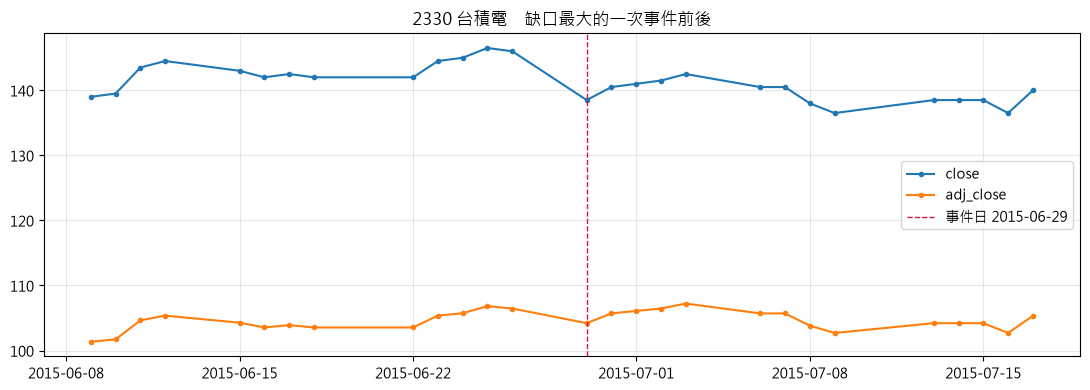

事件前一日 2015-06-26：原始 146.00　還原 106.46
事件當日   2015-06-29：原始 138.50　還原 104.21
原始價報酬 -5.14%　→　還原後 -2.11%


In [5]:
if len(events):
    # 挑原始價跳空最大的那次事件（不是最近一次），示範效果才明顯
    gaps = {}
    for d in events["date"]:
        prior = df.index[df.index < d]
        if len(prior) and d in df.index:
            gaps[d] = abs(df.loc[d, "close"] / df.loc[prior[-1], "close"] - 1)
    ev = max(gaps, key=gaps.get)
    print(f"共 {len(gaps)} 次事件，挑缺口最大的 {ev.date()}（原始價跳空 {gaps[ev]:.1%}）")

    window = df.loc[ev - pd.Timedelta(days=20): ev + pd.Timedelta(days=20)]

    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(window.index, window["close"], marker="o", ms=3, label="close")
    ax.plot(window.index, window["adj_close"], marker="o", ms=3, label="adj_close")
    ax.axvline(ev, color="crimson", ls="--", lw=1, label=f"事件日 {ev.date()}")
    ax.set_title(f"{STOCK_ID} {name}　缺口最大的一次事件前後")
    ax.legend()
    plt.tight_layout()
    plt.show()

    prev = window.index[window.index < ev][-1]
    print(f"事件前一日 {prev.date()}：原始 {window.loc[prev, 'close']:.2f}　"
          f"還原 {window.loc[prev, 'adj_close']:.2f}")
    print(f"事件當日   {ev.date()}：原始 {window.loc[ev, 'close']:.2f}　"
          f"還原 {window.loc[ev, 'adj_close']:.2f}")
    print(f"原始價報酬 {(window.loc[ev, 'close'] / window.loc[prev, 'close'] - 1) * 100:+.2f}%"
          f"　→　還原後 {(window.loc[ev, 'adj_close'] / window.loc[prev, 'adj_close'] - 1) * 100:+.2f}%")
else:
    print(f"{STOCK_ID} 期間內沒有事件")

### 2.3 基本統計與年化波動率

報酬與波動率都用 **`adj_close`** 計算。用 `close` 的話，每次除權息都會被算成一次下跌，
長期報酬被系統性低估、波動率則被高估。下面把兩者都算出來對照，差距就是「不做還原
會錯多少」。

年化波動率 = 日報酬標準差 × √252（一年約 252 個交易日）。

In [6]:
desc = df[["open", "high", "low", "close", "adj_close", "volume"]].describe().T
desc["count"] = desc["count"].astype(int)

ret_adj = df["adj_close"].pct_change().dropna()
ret_raw = df["close"].pct_change().dropna()
years = (df.index[-1] - df.index[0]).days / 365.25

stats = pd.DataFrame({
    "用 adj_close（正確）": {
        "年化波動率": f"{ret_adj.std() * np.sqrt(252):.2%}",
        "累積報酬": f"{df['adj_close'].iloc[-1] / df['adj_close'].iloc[0] - 1:+.1%}",
        "年化報酬(CAGR)": f"{(df['adj_close'].iloc[-1] / df['adj_close'].iloc[0]) ** (1 / years) - 1:+.2%}",
        "最大單日漲幅": f"{ret_adj.max():+.2%}",
        "最大單日跌幅": f"{ret_adj.min():+.2%}",
    },
    "用 close（錯誤示範）": {
        "年化波動率": f"{ret_raw.std() * np.sqrt(252):.2%}",
        "累積報酬": f"{df['close'].iloc[-1] / df['close'].iloc[0] - 1:+.1%}",
        "年化報酬(CAGR)": f"{(df['close'].iloc[-1] / df['close'].iloc[0]) ** (1 / years) - 1:+.2%}",
        "最大單日漲幅": f"{ret_raw.max():+.2%}",
        "最大單日跌幅": f"{ret_raw.min():+.2%}",
    },
})

print(f"{STOCK_ID} {name}　期間 {years:.1f} 年")
display(stats)
display(desc)

2330 台積電　期間 11.7 年

,用 adj_close（正確）,用 close（錯誤示範）
年化波動率,27.31%,27.40%
累積報酬,+2318.4%,+1663.4%
年化報酬(CAGR),+31.29%,+27.79%
最大單日漲幅,+9.98%,+9.98%
最大單日跌幅,-9.98%,-9.98%


,count,mean,std,min,25%,50%,75%,max
open,2855,565.290368,512.590373,118.0,221.0,440.0,614.0,2510.0
high,2855,569.890893,517.813192,121.0,223.0,442.0,618.0,2535.0
low,2855,560.769177,508.434682,112.5,220.0,435.0,608.0,2490.0
close,2855,565.263222,512.77364,115.0,221.25,437.0,613.0,2510.0
adj_close,2855,529.866718,520.487991,86.53,182.6,394.98,561.52,2502.63
volume,2855,36709402.083713,19743428.28727,1535230.0,24009671.5,32370342.0,43950900.5,176166037.0


## 3. 還原真的有效嗎：極端案例與定義性檢查

上面的圖是「看起來對」，這一節是「數字上對」。

挑價格變動最誇張的四次公司行動，把還原前後的單日報酬並排。如果還原是對的，
原始價那些一天翻倍 / 腰斬的數字，還原後應該落回正常的日內波動範圍
（台股漲跌幅上限 ±10%）。

這一整類事件都是 Phase 1 實跑時才發現的——一開始只處理了除權息，減資與面額變更
是靠 validator 的 `price_jump` 標記才被揪出來的（見 `docs/data_source.md`）。

In [7]:
cases = conn.execute(
    """
    SELECT c.stock_id, s.name, c.ex_date, c.action_type, c.before_price, c.after_price
    FROM corporate_actions c JOIN stocks s ON s.stock_id = c.stock_id
    ORDER BY ABS(c.after_price / c.before_price - 1) DESC LIMIT 4
    """
).fetchall()

rows = []
for sid, nm, ex_date, kind, before, after in cases:
    d = get_prices(sid)
    ev = pd.Timestamp(ex_date)
    prior = d.index[d.index < ev]
    if not len(prior) or ev not in d.index:
        continue
    prev = prior[-1]
    rows.append({
        "股票": f"{sid} {nm}",
        "日期": ex_date,
        "事件": {"capital_reduction": "減資", "split": "面額變更"}.get(kind, kind),
        "官方參考價": f"{before} → {after}",
        "原始價報酬": f"{d.loc[ev, 'close'] / d.loc[prev, 'close'] - 1:+.1%}",
        "還原後報酬": f"{d.loc[ev, 'adj_close'] / d.loc[prev, 'adj_close'] - 1:+.2%}",
    })

pd.DataFrame(rows).set_index("股票")

,日期,事件,官方參考價,原始價報酬,還原後報酬
股票,,,,,
2603 長榮,2022-09-19,減資,80.8 → 187.0,+109.2%,-9.62%
2609 陽明,2017-05-04,減資,6.15 → 13.16,+116.3%,+1.13%
6919 康霈*,2025-07-21,面額變更,1215.0 → 121.5,-89.0%,+9.88%
2327 國巨*,2025-08-25,面額變更,546.0 → 136.5,-73.8%,+4.76%


In [8]:
# 定義性檢查：後還原的定義是「最新一天不動」，所以每一檔最新一天的
# adj_close 都必須等於 close。這條不成立就代表方向搞反成前還原了。
mismatch = []
for sid in get_universe():
    d = get_prices(sid, conn=conn)
    if len(d) and abs(d["adj_close"].iloc[-1] - d["close"].iloc[-1]) > 0.011:
        mismatch.append(sid)

print(f"最新一天 adj_close != close 的股票：{mismatch if mismatch else '無'}"
      f"（檢查了 {len(get_universe())} 檔）")

最新一天 adj_close != close 的股票：無（檢查了 38 檔）


## 4. 全 universe 資料覆蓋率

一檔股票「有資料」不代表「資料完整」。中間缺幾天，回測就會把 t−1 到 t+1 當成
一天的報酬，算出不存在的漲跌。

**交易日曆怎麼來的**：台股沒有免費的官方交易日曆 API，這裡用「全 universe 所有
出現過的日期取聯集」當作觀測到的交易日曆。只要有任一檔在某天有成交，那天就是
交易日。38 檔涵蓋各主要產業，這個近似相當可靠。

每檔的「應有天數」只算它自己上市期間（第一筆 ~ 最後一筆）內的交易日，
新上市股票不會因為上市前沒資料而被算成缺漏。

In [9]:
all_prices = pd.read_sql("SELECT stock_id, date FROM prices", conn)
calendar = pd.DatetimeIndex(sorted(pd.to_datetime(all_prices["date"].unique())))
print(f"觀測到的交易日曆：{len(calendar):,} 天（{calendar[0].date()} ~ {calendar[-1].date()}）")

coverage = []
for sid, group in all_prices.groupby("stock_id"):
    dates = pd.DatetimeIndex(sorted(pd.to_datetime(group["date"])))
    expected = calendar[(calendar >= dates[0]) & (calendar <= dates[-1])]
    coverage.append({
        "stock_id": sid,
        "名稱": conn.execute("SELECT name FROM stocks WHERE stock_id = ?", (sid,)).fetchone()[0],
        "起": dates[0].date(), "訖": dates[-1].date(),
        "實際天數": len(dates), "應有天數": len(expected),
        "缺漏": len(expected) - len(dates),
    })

coverage = pd.DataFrame(coverage).set_index("stock_id")
coverage["覆蓋率"] = (coverage["實際天數"] / coverage["應有天數"]).map("{:.2%}".format)

print(f"平均覆蓋率 {coverage['實際天數'].sum() / coverage['應有天數'].sum():.2%}，"
      f"完全無缺漏的有 {(coverage['缺漏'] == 0).sum()} 檔")
coverage.sort_values("缺漏", ascending=False).head(10)

觀測到的交易日曆：2,855 天（2015-01-05 ~ 2026-09-18）


平均覆蓋率 99.86%，完全無缺漏的有 21 檔


,名稱,起,訖,實際天數,應有天數,缺漏,覆蓋率
stock_id,,,,,,,
2327,國巨*,2015-01-05,2026-09-18,2820,2855,35,98.77%
2492,華新科,2015-01-05,2026-09-18,2833,2855,22,99.23%
6442,光聖,2015-01-05,2026-09-18,2833,2855,22,99.23%
6919,康霈*,2022-12-26,2026-09-18,891,902,11,98.78%
8033,雷虎,2015-01-05,2026-09-18,2845,2855,10,99.65%
2609,陽明,2015-01-05,2026-09-18,2846,2855,9,99.68%
2317,鴻海,2015-01-05,2026-09-18,2847,2855,8,99.72%
2603,長榮,2015-01-05,2026-09-18,2848,2855,7,99.75%
3026,禾伸堂,2015-01-05,2026-09-18,2848,2855,7,99.75%


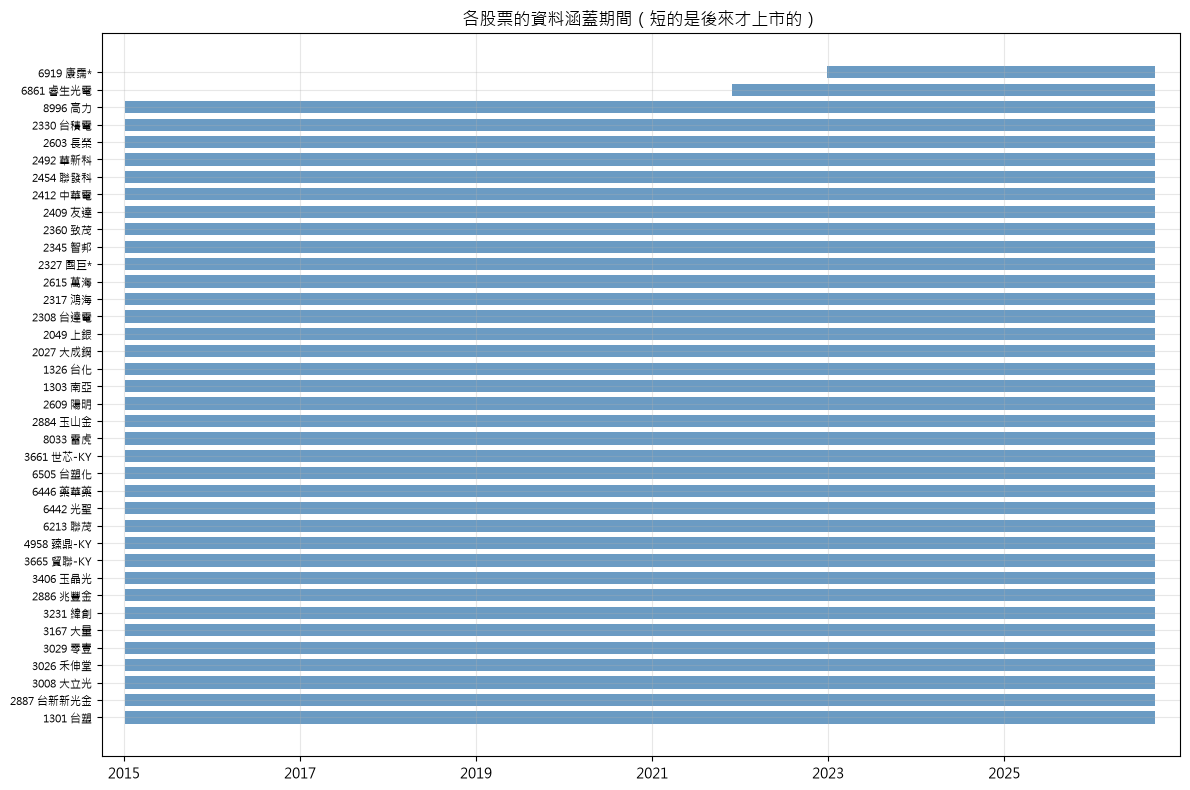

In [10]:
fig, ax = plt.subplots(figsize=(12, 8))
ordered = coverage.sort_values("起")
ax.barh(range(len(ordered)),
        [(pd.Timestamp(r["訖"]) - pd.Timestamp(r["起"])).days for _, r in ordered.iterrows()],
        left=[pd.Timestamp(r["起"]).toordinal() for _, r in ordered.iterrows()],
        height=0.7, color="steelblue", alpha=0.8)
ax.set_yticks(range(len(ordered)))
ax.set_yticklabels([f"{i} {r['名稱']}" for i, r in ordered.iterrows()], fontsize=8)
ax.set_xlim(pd.Timestamp("2014-10-01").toordinal(), pd.Timestamp("2026-12-31").toordinal())
ax.set_xticks([pd.Timestamp(f"{y}-01-01").toordinal() for y in range(2015, 2027, 2)])
ax.set_xticklabels(range(2015, 2027, 2))
ax.set_title("各股票的資料涵蓋期間（短的是後來才上市的）")
plt.tight_layout()
plt.show()

## 5. 隔離區（quarantine）：被擋下來的資料是什麼

`data_quarantine` 記錄 validator 認為有問題的資料。它分兩種，**不是全部都被丟掉**：

- **致命（fatal）**：資料自相矛盾（例如最高價比最低價低），不寫進 `prices`
- **標記（flag）**：可能是真的，只是罕見到值得人看一眼，**照樣寫進 `prices`**，
  但記一筆備查

所以這張表的定位是「人應該看一眼的東西」，不是「被拒絕的東西」。
一列違反幾條規則就記幾筆，所以筆數會大於列數。

,筆數,涉及檔數,涉及天數,處置
原因,,,,
low_gt_open,234,4,223,標記但照常寫入
high_lt_open,158,4,151,標記但照常寫入
non_positive_price,36,10,36,不寫入 prices
price_jump,9,4,9,標記但照常寫入
non_positive_open,3,2,3,標記但照常寫入


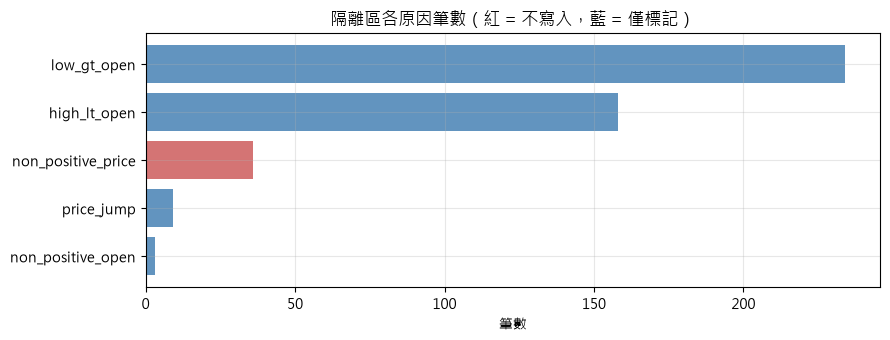

In [11]:
quarantine = pd.read_sql(
    """
    SELECT reason AS 原因, COUNT(*) AS 筆數,
           COUNT(DISTINCT stock_id) AS 涉及檔數, COUNT(DISTINCT date) AS 涉及天數
    FROM data_quarantine GROUP BY reason ORDER BY COUNT(*) DESC
    """,
    conn,
).set_index("原因")

FATAL = {"missing_price", "high_lt_low", "high_lt_close", "low_gt_close",
         "non_positive_price", "negative_volume", "duplicate_date"}
quarantine["處置"] = ["不寫入 prices" if r in FATAL else "標記但照常寫入"
                      for r in quarantine.index]

display(quarantine)

fig, ax = plt.subplots(figsize=(9, 3.5))
colors = ["indianred" if p == "不寫入 prices" else "steelblue" for p in quarantine["處置"]]
ax.barh(quarantine.index[::-1], quarantine["筆數"][::-1], color=colors[::-1], alpha=0.85)
ax.set_title("隔離區各原因筆數（紅 = 不寫入，藍 = 僅標記）")
ax.set_xlabel("筆數")
plt.tight_layout()
plt.show()

In [12]:
# 被標記最多的股票，以及它們各自的期間——如果集中在少數幾檔的特定期間，
# 通常代表那是某種結構性差異，而不是隨機的資料錯誤。
by_stock = pd.read_sql(
    """
    SELECT q.stock_id, s.name AS 名稱, q.reason AS 原因, COUNT(*) AS 筆數,
           MIN(q.date) AS 最早, MAX(q.date) AS 最晚
    FROM data_quarantine q JOIN stocks s ON s.stock_id = q.stock_id
    WHERE q.reason IN ('low_gt_open', 'high_lt_open')
    GROUP BY q.stock_id, q.reason ORDER BY COUNT(*) DESC
    """,
    conn,
).set_index(["stock_id", "原因"])

by_stock

名稱  筆數          最早          最晚
stock_id 原因                                            
6919     low_gt_open    康霈*  89  2022-12-26  2024-09-23
6446     low_gt_open    藥華藥  72  2015-01-21  2016-07-15
         high_lt_open   藥華藥  71  2015-01-09  2016-07-06
6861     low_gt_open   睿生光電  38  2021-11-30  2023-03-03
6442     low_gt_open     光聖  35  2015-01-05  2015-07-13
6861     high_lt_open  睿生光電  33  2021-12-13  2022-11-30
6919     high_lt_open   康霈*  30  2022-12-27  2024-09-25
6442     high_lt_open    光聖  24  2015-02-03  2015-06-16

### 每一類的解釋

驗收標準不是「隔離區是空的」，而是**裡面每一筆都解釋得出來**。

| 原因 | 處置 | 這是什麼 |
|---|---|---|
| `low_gt_open` / `high_lt_open` | 僅標記 | **興櫃時期的報價**。上表看得出來它們全部集中在 4 檔股票各自上市前的期間，之後就再也沒出現。興櫃是議價成交、沒有集合競價，`open` 跟 `high`/`low` 不是同一套口徑（那段期間報價出現 `138.64` 這種不符合台股跳動單位的數字）。但 `close`/`high`/`low` 本身合理，而回測用的是 `close`——為了一個對不上的 `open` 把整天丟掉，會在序列中間開洞，反而製造假報酬 |
| `non_positive_price` | 不寫入 | **停牌或無成交日**。FinMind 對這些日子回傳 O/H/L/C 全為 0、成交量 0。那天本來就沒有價格，擋掉是對的 |
| `non_positive_open` | 僅標記 | **上市首日或停牌復牌當天**沒有開盤參考價，FinMind 填 0，但那天是真的有成交的 |
| `price_jump` | 僅標記 | 單日漲跌超過 15%。除權息與減資 / 面額變更日**已經被排除**（那些是已知會跳空的日子），剩下的集中在興櫃期間——興櫃沒有漲跌幅限制，那些是真實波動 |

`price_jump` 這條規則的價值在這裡值得特別講：**減資與面額變更這一整類事件，
當初就是被它標出來才發現漏掉的**。原本的還原只處理除權息，2609 陽明 2017 年的
減資會被回測看成一天暴漲 116%。它做到了一條品質規則該做的事——
不是擋下錯誤資料，而是讓「我們不知道自己不知道的事」浮出水面。

## 6. 結論與已知限制

### 可以用來做什麼

- 38 檔、2015 年至今約 10.5 萬列日線，涵蓋各主要產業
- 還原價同時處理除權息、減資、面額變更，經官方參考價交叉驗證
- 整條 pipeline 冪等、可增量更新、失敗會隔離而不是靜默丟棄

### 已知限制（Phase 2 之後要留意）

1. **universe 只有 38 檔，而且是「現在還活著」的股票**。已下市的公司完全不在裡面，
   直接拿來回測會有**存活者偏誤**，績效會虛高。`stocks.is_active` 已經預留了欄位，
   但目前沒有任何已下市股票的歷史資料
2. **只涵蓋上市（TWSE），不含上櫃（TPEx）**
3. **`listing_date` 全部是空的**：FinMind 的 `date` 欄位是資料更新日不是上市日，
   目前沒有可靠來源
4. **交易日曆是推估的**，用全 universe 日期的聯集。若某天 38 檔全部沒有交易
   （極端情況），那天不會被認定為交易日
5. **隔離區的紀錄不會因為規則改變而失效**。改了 validator 的規則之後，
   舊規則產生的紀錄還留在表裡。目前這個資料庫是規則定案後整個重建的，所以是乾淨的；
   之後若再調規則，要記得用 `run_ingest --full` 重跑，或先清掉舊紀錄
6. **資料為 FinMind 二手彙整**，理論上仍可能有轉錄延遲；高風險用途應以
   TWSE OpenAPI / MOPS 二次驗證

### 下一步

Phase 2：回測引擎。所有資料都透過 `database/data_access.py` 取得，
回測引擎不會自己碰 SQL。

In [13]:
conn.close()
print("檢查完成。")

檢查完成。
